> **Atribución.** Esta libreta es material del curso de Aprendizaje Profundo (UAM), adaptado al español a partir de los tutoriales de [Naoki Shibuya](https://github.com/naokishibuya/deep-learning) y de los ejemplos de Udacity citados en la sección de referencias. No es un trabajo original mío: mi aporte es la ejecución, la experimentación con hiperparámetros y, en esta versión, una arquitectura modificada: más filtros en generador y discriminador, Dropout en el discriminador y nuevos hiperparámetros de Adam y LeakyReLU.

# Generador Adversario Convolucional Profundo (DCGAN) con MNIST

Utiliza redes convolucionales profundas en el generador y el discriminador.

In [ ]:
import numpy as np
from scipy.io import loadmat
import keras
import keras.backend as K
from keras.layers import Dense, Activation, LeakyReLU, BatchNormalization
from keras.layers import Conv2D, Conv2DTranspose, Reshape, Flatten
from keras.models import Sequential
from tensorflow.keras.optimizers import Adam
from sklearn.model_selection import train_test_split
import matplotlib.pyplot as plt
from tensorflow.keras.layers import Dropout

%matplotlib inline

In [ ]:
import tensorflow as tf
print(tf.__version__)

2.19.0


## Cargando el Conjunto de Datos MNIST



In [ ]:
(X_train, y_train), (X_test, y_test) = keras.datasets.mnist.load_data()

Solo utilizamos las imágenes, no las etiquetas categóricas.

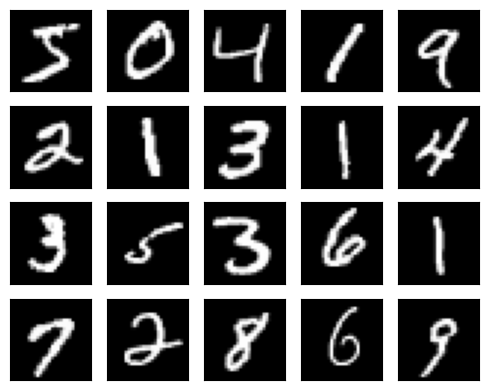

In [ ]:
plt.figure(figsize=(5, 4))
for i in range(20):
    plt.subplot(4, 5, i+1)
    plt.imshow(X_train[i], cmap='gray')
    plt.xticks([])
    plt.yticks([])
plt.tight_layout()
plt.show()

## Preprocesamiento y Desprocesamiento

Como es habitual, necesitamos realizar un preprocesamiento y posterior desprocesamiento de las imágenes.

Como veremos más adelante, el generador utiliza una activación `tanh`, por lo que debemos preprocesar los datos de la imagen para que estén en el rango entre -1 y 1.

In [ ]:
def preprocess(x):
    x = x.reshape(-1, 28, 28, 1) # 28,28,1
    x = np.float64(x)
    x = (x / 255 - 0.5) * 2
    x = np.clip(x, -1, 1)
    return x

def deprocess(x):
    x = (x / 2 + 1) * 255
    x = np.clip(x, 0, 255)
    x = np.uint8(x)
    x = x.reshape(28, 28)
    return x

Aplica el preprocesamiento a las imágenes de entrenamiento y prueba (que son las imágenes reales en contraposición a las imágenes generadas).

In [ ]:
X_train_real = preprocess(X_train)
X_test_real  = preprocess(X_test)

## Generador

El artículo original de DCGAN [[3]](#ref3) propone la siguiente arquitectura de red generadora.

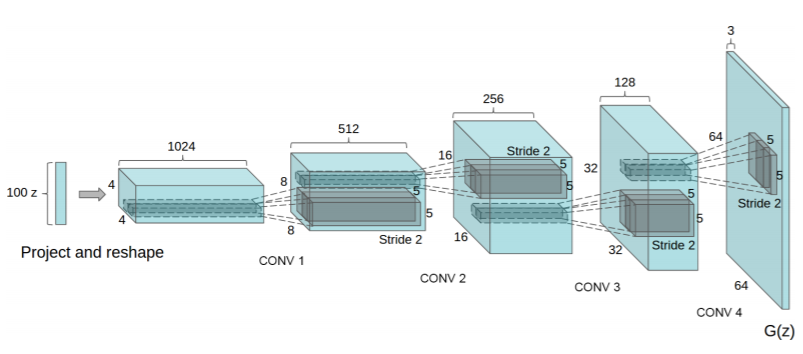

En este cuaderno, utilicé redes más pequeñas que las que propone el artículo original [[3]](#ref3) debido a que el tamaño de nuestra imagen es de 28x28 y solo tiene 1 canal.

El generador toma una muestra latente de 100 números aleatorios y genera una imagen de 28x28 con 1 canal.

La primera capa acepta 784 puntos de datos. Luego, reconfigura los datos a una forma de 7x7 con 16 filtros. Después, dos capas de convolución transpuesta aumentarán el tamaño de los datos a 28x28.


In [ ]:
def make_generator(input_size, leaky_alpha):
    return Sequential([
        Dense(128 * 7 * 7, input_shape=(input_size,)),
        Reshape((7, 7, 128)),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        Conv2DTranspose(64, kernel_size=5, strides=2, padding='same'),
        BatchNormalization(),
        LeakyReLU(alpha=leaky_alpha),

        Conv2DTranspose(1, kernel_size=5, strides=2, padding='same', activation='tanh')
    ])


## Discriminador


El discriminador es un clasificador que determina si la imagen de entrada es real o falsa.

Es una red neuronal convolucional que toma una imagen de 28x28 con 1 canal. Se espera que los valores en la imagen estén en el rango entre -1 y 1.

La activación de la capa de salida es `sigmoid`, y el discriminador produce una probabilidad de que la imagen sea real.

Utilicé una capa completamente conectada con 784 (=28x28) neuronas. Para que este discriminador sea comparable, he utilizado el mismo número de neuronas en la última capa oculta completamente conectada y luego añadí capas de convolución antes de esta capa.

Nota: el uso de un número decreciente de filtros puede ser un poco inusual, pero lo hice para que la red del discriminador y la red del generador tengan un aumento similar en el número de neuronas de la red convolucional (con suerte, manteniendo un equilibrio en su capacidad).

In [ ]:
def make_discriminator(leaky_alpha):
    return Sequential([
        Conv2D(64, kernel_size=5, strides=2, padding='same', input_shape=(28, 28, 1)),
        LeakyReLU(alpha=leaky_alpha),
        Dropout(0.3),

        Conv2D(128, kernel_size=5, strides=2, padding='same'),
        LeakyReLU(alpha=leaky_alpha),
        Dropout(0.3),

        Flatten(),
        Dense(1, activation='sigmoid')
    ])


### Acerca de la Normalización por Lotes (Batch Normalization)

En cuanto a la normalización por lotes (batch normalization), esta se aplicó a la mayoría de las capas, pero no a todas. La siguiente cita proviene del artículo original de DCGAN [[3]](#ref3):

> Aplicar directamente la normalización por lotes a todas las capas resultó en oscilación de las muestras e inestabilidad del modelo. Esto se evitó al no aplicar la normalización por lotes a la capa de salida del generador y a la capa de entrada del discriminador.

## DCGAN

Conectamos el generador y el discriminador para crear un DCGAN.

La entrada al DCGAN es una muestra latente. El generador dentro del DCGAN produce una imagen que se alimenta al discriminador dentro del DCGAN. Por lo tanto, la salida del DCGAN es la probabilidad de que la imagen generada sea real.

In [ ]:
# beta_1 is the exponential decay rate for the 1st moment estimates in Adam optimizer
def make_DCGAN(sample_size, g_learning_rate, g_beta_1, d_learning_rate, d_beta_1, leaky_alpha):
    # clear first
    K.clear_session()

    # generator
    generator = make_generator(sample_size, leaky_alpha)

    # discriminator
    discriminator = make_discriminator(leaky_alpha)
    discriminator.compile(optimizer=Adam(learning_rate=d_learning_rate, beta_1=d_beta_1), loss='binary_crossentropy')

    # GAN
    gan = Sequential([generator, discriminator])
    gan.compile(optimizer=Adam(learning_rate=g_learning_rate, beta_1=g_beta_1), loss='binary_crossentropy')

    return gan, generator, discriminator

## Entrenamiento de DCGAN

A continuación, se presenta una función para generar muestras latentes.

In [ ]:
def make_latent_samples(n_samples, sample_size):
    #return np.random.uniform(-1, 1, size=(n_samples, sample_size))
    return np.random.normal(loc=0, scale=1, size=(n_samples, sample_size))

La siguiente es una función para establecer el discriminador como entrenable o no entrenable.

In [ ]:
def make_trainable(model, trainable):
    for layer in model.layers:
        layer.trainable = trainable

La siguiente es una función para crear un lote de etiquetas.

In [ ]:
def make_labels(size):
    return np.ones([size, 1]), np.zeros([size, 1])

Lo siguiente es para mostrar las pérdidas.

In [ ]:
def show_results(losses):
    labels = ['Classifier', 'Discriminator', 'Generator']
    losses = np.array(losses)

    fig, ax = plt.subplots()
    plt.plot(losses.T[0], label='Discriminator')
    plt.plot(losses.T[1], label='Generator')
    plt.title("Training Losses")
    plt.legend()
    plt.show()

Lo siguiente es para mostrar las imágenes generadas.

In [ ]:
def show_images(generated_images):
    n_images = len(generated_images)
    rows = 4
    cols = n_images//rows

    plt.figure(figsize=(cols, rows))
    for i in range(n_images):
        img = deprocess(generated_images[i])
        plt.subplot(rows, cols, i+1)
        plt.imshow(img, cmap='gray')
        plt.xticks([])
        plt.yticks([])
    plt.tight_layout()
    plt.show()

El entrenamiento de DCGAN es esencialmente el mismo que el entrenamiento de una GAN simple:

1. Establecer el discriminador como entrenable.
2. Entrenar el discriminador con imágenes reales con suavizado de etiquetas (etiquetas=1-suavizado).
3. Entrenar el discriminador con imágenes falsas generadas por el generador (etiquetas=0).
4. Establecer el discriminador como no entrenable.
5. Entrenar el DCGAN con imágenes generadas (etiquetas=1).

Repetimos este proceso muchas veces hasta que la pérdida del discriminador y la pérdida del generador se estabilicen.

In [ ]:
def train(
    g_learning_rate,   # learning rate for the generator
    g_beta_1,          # the exponential decay rate for the 1st moment estimates in Adam optimizer
    d_learning_rate,   # learning rate for the discriminator
    d_beta_1,          # the exponential decay rate for the 1st moment estimates in Adam optimizer
    leaky_alpha,
    smooth=0.1,        # label smoothing
    sample_size=100,   # latent sample size (i.e. 100 random numbers)
    epochs=100,
    batch_size=128,    # train batch size
    eval_size=16,      # evaluate size
    show_details=True):

    # labels for the batch size and the test size
    y_train_real, y_train_fake = make_labels(batch_size)
    y_eval_real,  y_eval_fake  = make_labels(eval_size)

    # create a GAN, a generator and a discriminator
    gan, generator, discriminator = make_DCGAN(sample_size, g_learning_rate, g_beta_1, d_learning_rate, d_beta_1, leaky_alpha)

    losses = []
    for e in range(epochs):
        for i in range(len(X_train_real)//batch_size):
            # real MNIST digit images
            X_batch_real = X_train_real[i*batch_size:(i+1)*batch_size]

            # latent samples and the generated digit images
            latent_samples = make_latent_samples(batch_size, sample_size)
            X_batch_fake = generator.predict_on_batch(latent_samples)

            # train the discriminator to detect real and fake images
            make_trainable(discriminator, True)
            discriminator.train_on_batch(X_batch_real, y_train_real * (1 - smooth))
            discriminator.train_on_batch(X_batch_fake, y_train_fake)

            # train the generator via GAN
            make_trainable(discriminator, False)
            gan.train_on_batch(latent_samples, y_train_real)

        # evaluate
        X_eval_real = X_test_real[np.random.choice(len(X_test_real), eval_size, replace=False)]

        latent_samples = make_latent_samples(eval_size, sample_size)
        X_eval_fake = generator.predict_on_batch(latent_samples)

        d_loss  = discriminator.test_on_batch(X_eval_real, y_eval_real)
        d_loss += discriminator.test_on_batch(X_eval_fake, y_eval_fake)
        g_loss  = gan.test_on_batch(latent_samples, y_eval_real) # we want the fake to be realistic!

        losses.append((d_loss, g_loss))

        print("Epoch:{:>3}/{} Discriminator Loss:{:>7.4f} Generator Loss:{:>7.4f}".format(
            e+1, epochs, d_loss, g_loss))

        if show_details and (e+1)%10==0:
            show_images(X_eval_fake)
    if show_details:
        show_results(losses)
    return generator

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
/usr/local/lib/python3.12/dist-packages/keras/src/layers/activations/leaky_relu.py:41: UserWarning: Argument `alpha` is deprecated. Use `negative_slope` instead.
  warnings.warn(
/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch:  1/100 Discriminator Loss: 1.0201 Generator Loss: 0.8133
Epoch:  2/100 Discriminator Loss: 1.2085 Generator Loss: 0.8604
Epoch:  3/100 Discriminator Loss: 1.2481 Generator Loss: 0.8828
Epoch:  4/100 Discriminator Loss: 1.2636 Generator Loss: 0.9020
Epoch:  5/100 Discriminator Loss: 1.2818 Generator Loss: 0.9056
Epoch:  6/100 Discriminator Loss: 1.2951 Generator Loss: 0.9030
Epoch:  7/100 Discriminator Loss: 1.3047 Generator Loss: 0.8998
Epoch:  8/100 Discriminator Loss: 1.3116 Generator Loss: 0.8971
Epoch:  9/100 Discriminator Loss: 1.3168 Generator Loss: 0.8950
Epoch: 10/100 Discriminator Loss: 1.3208 Generator Loss: 0.8937


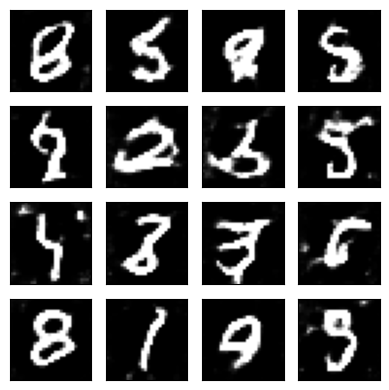

Epoch: 11/100 Discriminator Loss: 1.3235 Generator Loss: 0.8930
Epoch: 12/100 Discriminator Loss: 1.3256 Generator Loss: 0.8930
Epoch: 13/100 Discriminator Loss: 1.3271 Generator Loss: 0.8934
Epoch: 14/100 Discriminator Loss: 1.3281 Generator Loss: 0.8941
Epoch: 15/100 Discriminator Loss: 1.3288 Generator Loss: 0.8952
Epoch: 16/100 Discriminator Loss: 1.3295 Generator Loss: 0.8962
Epoch: 17/100 Discriminator Loss: 1.3299 Generator Loss: 0.8973
Epoch: 18/100 Discriminator Loss: 1.3302 Generator Loss: 0.8985
Epoch: 19/100 Discriminator Loss: 1.3305 Generator Loss: 0.8998
Epoch: 20/100 Discriminator Loss: 1.3307 Generator Loss: 0.9009


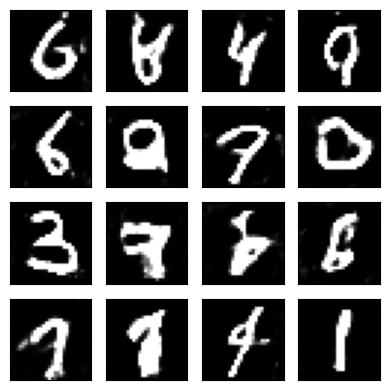

Epoch: 21/100 Discriminator Loss: 1.3308 Generator Loss: 0.9020
Epoch: 22/100 Discriminator Loss: 1.3310 Generator Loss: 0.9030
Epoch: 23/100 Discriminator Loss: 1.3311 Generator Loss: 0.9039
Epoch: 24/100 Discriminator Loss: 1.3312 Generator Loss: 0.9050
Epoch: 25/100 Discriminator Loss: 1.3312 Generator Loss: 0.9060
Epoch: 26/100 Discriminator Loss: 1.3312 Generator Loss: 0.9069
Epoch: 27/100 Discriminator Loss: 1.3313 Generator Loss: 0.9077
Epoch: 28/100 Discriminator Loss: 1.3313 Generator Loss: 0.9086
Epoch: 29/100 Discriminator Loss: 1.3313 Generator Loss: 0.9093
Epoch: 30/100 Discriminator Loss: 1.3313 Generator Loss: 0.9101


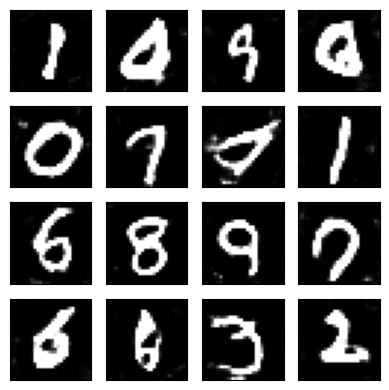

Epoch: 31/100 Discriminator Loss: 1.3313 Generator Loss: 0.9108
Epoch: 32/100 Discriminator Loss: 1.3312 Generator Loss: 0.9116
Epoch: 33/100 Discriminator Loss: 1.3311 Generator Loss: 0.9125
Epoch: 34/100 Discriminator Loss: 1.3311 Generator Loss: 0.9132
Epoch: 35/100 Discriminator Loss: 1.3309 Generator Loss: 0.9140
Epoch: 36/100 Discriminator Loss: 1.3308 Generator Loss: 0.9147
Epoch: 37/100 Discriminator Loss: 1.3307 Generator Loss: 0.9154
Epoch: 38/100 Discriminator Loss: 1.3306 Generator Loss: 0.9161
Epoch: 39/100 Discriminator Loss: 1.3304 Generator Loss: 0.9168
Epoch: 40/100 Discriminator Loss: 1.3303 Generator Loss: 0.9176


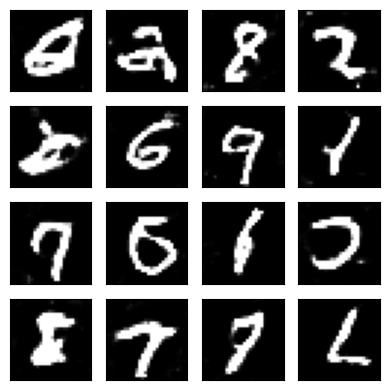

Epoch: 41/100 Discriminator Loss: 1.3301 Generator Loss: 0.9184
Epoch: 42/100 Discriminator Loss: 1.3300 Generator Loss: 0.9192
Epoch: 43/100 Discriminator Loss: 1.3298 Generator Loss: 0.9199
Epoch: 44/100 Discriminator Loss: 1.3297 Generator Loss: 0.9206
Epoch: 45/100 Discriminator Loss: 1.3294 Generator Loss: 0.9213
Epoch: 46/100 Discriminator Loss: 1.3293 Generator Loss: 0.9220
Epoch: 47/100 Discriminator Loss: 1.3291 Generator Loss: 0.9227
Epoch: 48/100 Discriminator Loss: 1.3289 Generator Loss: 0.9234
Epoch: 49/100 Discriminator Loss: 1.3287 Generator Loss: 0.9242
Epoch: 50/100 Discriminator Loss: 1.3285 Generator Loss: 0.9248


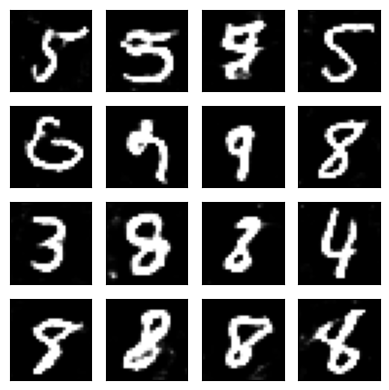

Epoch: 51/100 Discriminator Loss: 1.3283 Generator Loss: 0.9255
Epoch: 52/100 Discriminator Loss: 1.3280 Generator Loss: 0.9262
Epoch: 53/100 Discriminator Loss: 1.3278 Generator Loss: 0.9269
Epoch: 54/100 Discriminator Loss: 1.3276 Generator Loss: 0.9276
Epoch: 55/100 Discriminator Loss: 1.3274 Generator Loss: 0.9283
Epoch: 56/100 Discriminator Loss: 1.3272 Generator Loss: 0.9289
Epoch: 57/100 Discriminator Loss: 1.3270 Generator Loss: 0.9296
Epoch: 58/100 Discriminator Loss: 1.3268 Generator Loss: 0.9303
Epoch: 59/100 Discriminator Loss: 1.3266 Generator Loss: 0.9309
Epoch: 60/100 Discriminator Loss: 1.3264 Generator Loss: 0.9316


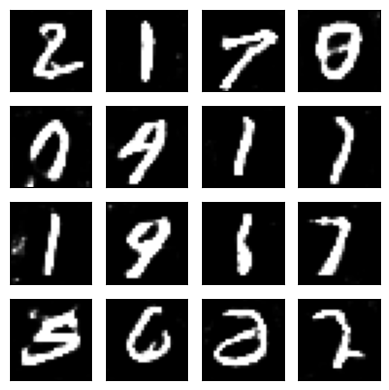

Epoch: 61/100 Discriminator Loss: 1.3262 Generator Loss: 0.9322
Epoch: 62/100 Discriminator Loss: 1.3260 Generator Loss: 0.9328
Epoch: 63/100 Discriminator Loss: 1.3258 Generator Loss: 0.9334
Epoch: 64/100 Discriminator Loss: 1.3256 Generator Loss: 0.9340
Epoch: 65/100 Discriminator Loss: 1.3254 Generator Loss: 0.9346
Epoch: 66/100 Discriminator Loss: 1.3253 Generator Loss: 0.9351
Epoch: 67/100 Discriminator Loss: 1.3251 Generator Loss: 0.9357
Epoch: 68/100 Discriminator Loss: 1.3249 Generator Loss: 0.9363
Epoch: 69/100 Discriminator Loss: 1.3248 Generator Loss: 0.9368
Epoch: 70/100 Discriminator Loss: 1.3246 Generator Loss: 0.9373


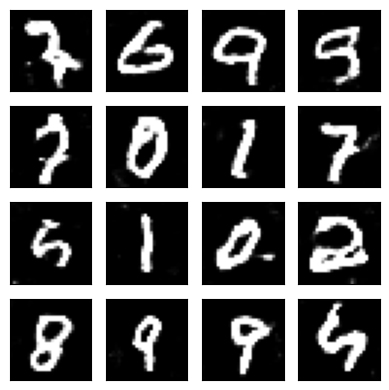

Epoch: 71/100 Discriminator Loss: 1.3244 Generator Loss: 0.9378
Epoch: 72/100 Discriminator Loss: 1.3243 Generator Loss: 0.9384
Epoch: 73/100 Discriminator Loss: 1.3241 Generator Loss: 0.9389
Epoch: 74/100 Discriminator Loss: 1.3240 Generator Loss: 0.9393
Epoch: 75/100 Discriminator Loss: 1.3238 Generator Loss: 0.9398
Epoch: 76/100 Discriminator Loss: 1.3237 Generator Loss: 0.9403
Epoch: 77/100 Discriminator Loss: 1.3235 Generator Loss: 0.9408
Epoch: 78/100 Discriminator Loss: 1.3233 Generator Loss: 0.9413
Epoch: 79/100 Discriminator Loss: 1.3232 Generator Loss: 0.9418
Epoch: 80/100 Discriminator Loss: 1.3230 Generator Loss: 0.9423


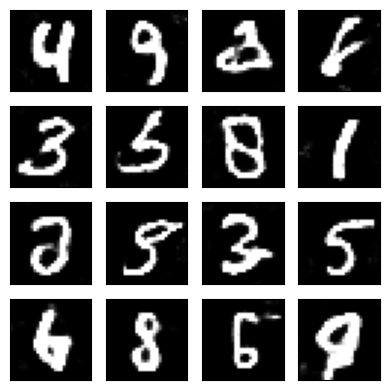

Epoch: 81/100 Discriminator Loss: 1.3229 Generator Loss: 0.9428
Epoch: 82/100 Discriminator Loss: 1.3227 Generator Loss: 0.9432
Epoch: 83/100 Discriminator Loss: 1.3226 Generator Loss: 0.9437
Epoch: 84/100 Discriminator Loss: 1.3224 Generator Loss: 0.9441
Epoch: 85/100 Discriminator Loss: 1.3223 Generator Loss: 0.9446
Epoch: 86/100 Discriminator Loss: 1.3221 Generator Loss: 0.9450
Epoch: 87/100 Discriminator Loss: 1.3220 Generator Loss: 0.9454
Epoch: 88/100 Discriminator Loss: 1.3218 Generator Loss: 0.9459
Epoch: 89/100 Discriminator Loss: 1.3217 Generator Loss: 0.9463
Epoch: 90/100 Discriminator Loss: 1.3216 Generator Loss: 0.9467


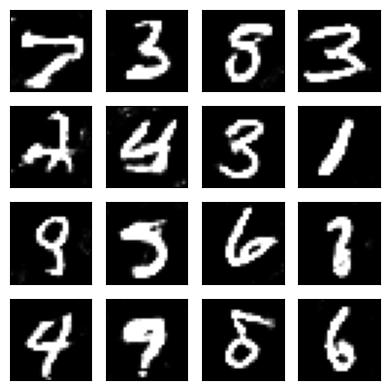

Epoch: 91/100 Discriminator Loss: 1.3214 Generator Loss: 0.9472
Epoch: 92/100 Discriminator Loss: 1.3213 Generator Loss: 0.9476
Epoch: 93/100 Discriminator Loss: 1.3211 Generator Loss: 0.9480
Epoch: 94/100 Discriminator Loss: 1.3210 Generator Loss: 0.9484
Epoch: 95/100 Discriminator Loss: 1.3209 Generator Loss: 0.9488
Epoch: 96/100 Discriminator Loss: 1.3208 Generator Loss: 0.9492
Epoch: 97/100 Discriminator Loss: 1.3207 Generator Loss: 0.9495
Epoch: 98/100 Discriminator Loss: 1.3205 Generator Loss: 0.9499
Epoch: 99/100 Discriminator Loss: 1.3204 Generator Loss: 0.9503
Epoch:100/100 Discriminator Loss: 1.3203 Generator Loss: 0.9507


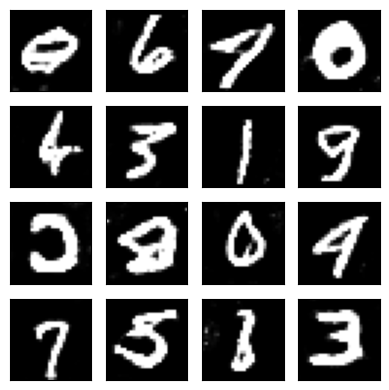

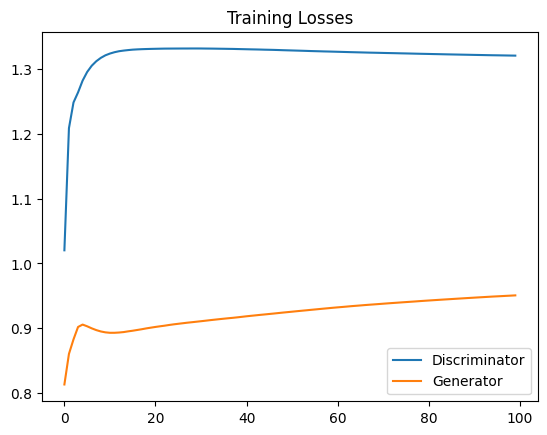

<Sequential name=sequential, built=True>

In [ ]:
train(
    g_learning_rate=0.0002,
    g_beta_1=0.5,
    d_learning_rate=0.0002,
    d_beta_1=0.5,
    leaky_alpha=0.2
)

Sin duda, es mucho mejor que los resultados del modelo simple de GAN para MNIST.

Epoch:  1/100 Discriminator Loss: 0.3427 Generator Loss: 7.4312
Epoch:  2/100 Discriminator Loss: 0.3421 Generator Loss: 7.1031
Epoch:  3/100 Discriminator Loss: 0.3768 Generator Loss: 6.4016
Epoch:  4/100 Discriminator Loss: 0.4131 Generator Loss: 5.7953
Epoch:  5/100 Discriminator Loss: 0.4543 Generator Loss: 5.2893
Epoch:  6/100 Discriminator Loss: 0.4890 Generator Loss: 4.9296
Epoch:  7/100 Discriminator Loss: 0.5190 Generator Loss: 4.6490
Epoch:  8/100 Discriminator Loss: 0.5449 Generator Loss: 4.4269
Epoch:  9/100 Discriminator Loss: 0.5684 Generator Loss: 4.2378
Epoch: 10/100 Discriminator Loss: 0.5905 Generator Loss: 4.0742


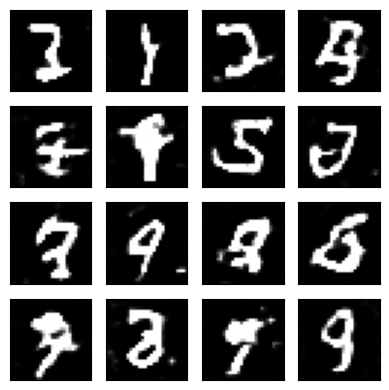

Epoch: 11/100 Discriminator Loss: 0.6103 Generator Loss: 3.9380
Epoch: 12/100 Discriminator Loss: 0.6289 Generator Loss: 3.8145
Epoch: 13/100 Discriminator Loss: 0.6456 Generator Loss: 3.7065
Epoch: 14/100 Discriminator Loss: 0.6601 Generator Loss: 3.6135
Epoch: 15/100 Discriminator Loss: 0.6735 Generator Loss: 3.5292
Epoch: 16/100 Discriminator Loss: 0.6858 Generator Loss: 3.4532
Epoch: 17/100 Discriminator Loss: 0.6971 Generator Loss: 3.3841
Epoch: 18/100 Discriminator Loss: 0.7074 Generator Loss: 3.3224
Epoch: 19/100 Discriminator Loss: 0.7170 Generator Loss: 3.2650
Epoch: 20/100 Discriminator Loss: 0.7261 Generator Loss: 3.2120


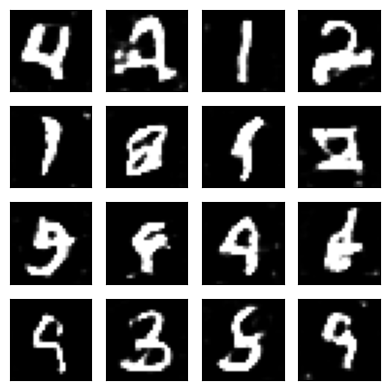

Epoch: 21/100 Discriminator Loss: 0.7341 Generator Loss: 3.1663
Epoch: 22/100 Discriminator Loss: 0.7421 Generator Loss: 3.1207
Epoch: 23/100 Discriminator Loss: 0.7491 Generator Loss: 3.0814
Epoch: 24/100 Discriminator Loss: 0.7561 Generator Loss: 3.0421
Epoch: 25/100 Discriminator Loss: 0.7626 Generator Loss: 3.0061
Epoch: 26/100 Discriminator Loss: 0.7690 Generator Loss: 2.9705
Epoch: 27/100 Discriminator Loss: 0.7750 Generator Loss: 2.9374
Epoch: 28/100 Discriminator Loss: 0.7807 Generator Loss: 2.9078
Epoch: 29/100 Discriminator Loss: 0.7861 Generator Loss: 2.8783
Epoch: 30/100 Discriminator Loss: 0.7913 Generator Loss: 2.8510


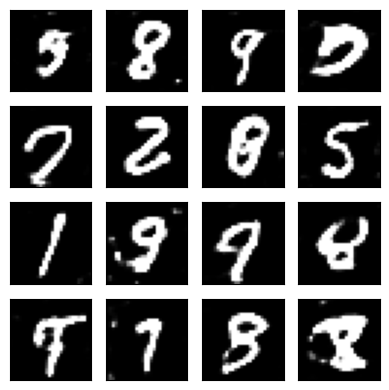

Epoch: 31/100 Discriminator Loss: 0.7963 Generator Loss: 2.8249
Epoch: 32/100 Discriminator Loss: 0.8011 Generator Loss: 2.7999
Epoch: 33/100 Discriminator Loss: 0.8056 Generator Loss: 2.7765
Epoch: 34/100 Discriminator Loss: 0.8101 Generator Loss: 2.7541
Epoch: 35/100 Discriminator Loss: 0.8145 Generator Loss: 2.7325
Epoch: 36/100 Discriminator Loss: 0.8188 Generator Loss: 2.7111
Epoch: 37/100 Discriminator Loss: 0.8224 Generator Loss: 2.6930
Epoch: 38/100 Discriminator Loss: 0.8262 Generator Loss: 2.6736
Epoch: 39/100 Discriminator Loss: 0.8299 Generator Loss: 2.6556
Epoch: 40/100 Discriminator Loss: 0.8334 Generator Loss: 2.6385


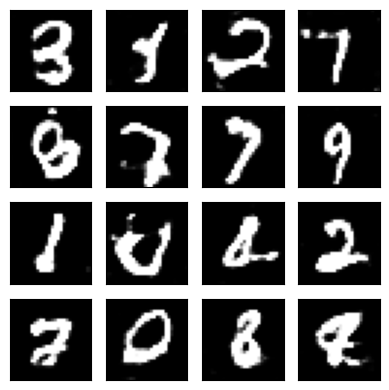

Epoch: 41/100 Discriminator Loss: 0.8368 Generator Loss: 2.6213
Epoch: 42/100 Discriminator Loss: 0.8402 Generator Loss: 2.6047
Epoch: 43/100 Discriminator Loss: 0.8434 Generator Loss: 2.5891
Epoch: 44/100 Discriminator Loss: 0.8465 Generator Loss: 2.5740
Epoch: 45/100 Discriminator Loss: 0.8497 Generator Loss: 2.5595
Epoch: 46/100 Discriminator Loss: 0.8526 Generator Loss: 2.5449
Epoch: 47/100 Discriminator Loss: 0.8554 Generator Loss: 2.5317
Epoch: 48/100 Discriminator Loss: 0.8582 Generator Loss: 2.5187
Epoch: 49/100 Discriminator Loss: 0.8608 Generator Loss: 2.5061
Epoch: 50/100 Discriminator Loss: 0.8634 Generator Loss: 2.4937


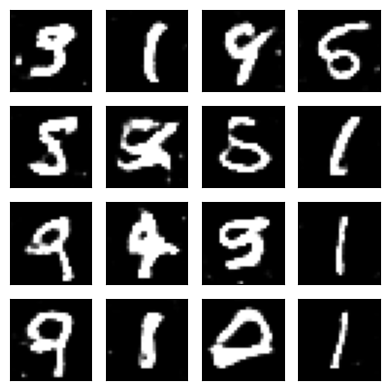

Epoch: 51/100 Discriminator Loss: 0.8659 Generator Loss: 2.4820
Epoch: 52/100 Discriminator Loss: 0.8684 Generator Loss: 2.4702
Epoch: 53/100 Discriminator Loss: 0.8708 Generator Loss: 2.4592
Epoch: 54/100 Discriminator Loss: 0.8732 Generator Loss: 2.4481
Epoch: 55/100 Discriminator Loss: 0.8755 Generator Loss: 2.4374
Epoch: 56/100 Discriminator Loss: 0.8779 Generator Loss: 2.4269
Epoch: 57/100 Discriminator Loss: 0.8802 Generator Loss: 2.4165
Epoch: 58/100 Discriminator Loss: 0.8823 Generator Loss: 2.4067
Epoch: 59/100 Discriminator Loss: 0.8844 Generator Loss: 2.3971
Epoch: 60/100 Discriminator Loss: 0.8865 Generator Loss: 2.3875


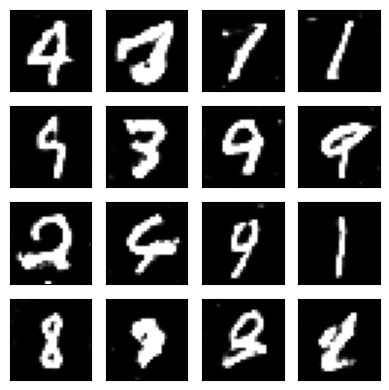

Epoch: 61/100 Discriminator Loss: 0.8886 Generator Loss: 2.3785
Epoch: 62/100 Discriminator Loss: 0.8906 Generator Loss: 2.3696
Epoch: 63/100 Discriminator Loss: 0.8926 Generator Loss: 2.3608
Epoch: 64/100 Discriminator Loss: 0.8944 Generator Loss: 2.3528
Epoch: 65/100 Discriminator Loss: 0.8963 Generator Loss: 2.3444
Epoch: 66/100 Discriminator Loss: 0.8982 Generator Loss: 2.3362
Epoch: 67/100 Discriminator Loss: 0.9000 Generator Loss: 2.3281
Epoch: 68/100 Discriminator Loss: 0.9018 Generator Loss: 2.3203
Epoch: 69/100 Discriminator Loss: 0.9036 Generator Loss: 2.3125
Epoch: 70/100 Discriminator Loss: 0.9053 Generator Loss: 2.3054


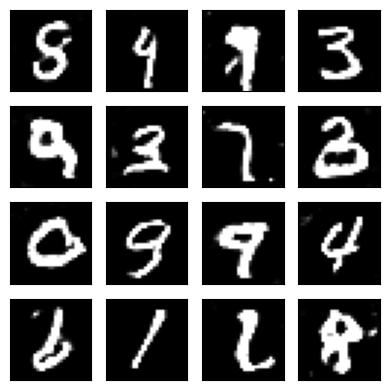

Epoch: 71/100 Discriminator Loss: 0.9070 Generator Loss: 2.2980
Epoch: 72/100 Discriminator Loss: 0.9087 Generator Loss: 2.2908
Epoch: 73/100 Discriminator Loss: 0.9103 Generator Loss: 2.2841
Epoch: 74/100 Discriminator Loss: 0.9119 Generator Loss: 2.2772
Epoch: 75/100 Discriminator Loss: 0.9135 Generator Loss: 2.2707
Epoch: 76/100 Discriminator Loss: 0.9150 Generator Loss: 2.2641
Epoch: 77/100 Discriminator Loss: 0.9166 Generator Loss: 2.2577
Epoch: 78/100 Discriminator Loss: 0.9181 Generator Loss: 2.2513
Epoch: 79/100 Discriminator Loss: 0.9196 Generator Loss: 2.2449
Epoch: 80/100 Discriminator Loss: 0.9211 Generator Loss: 2.2389


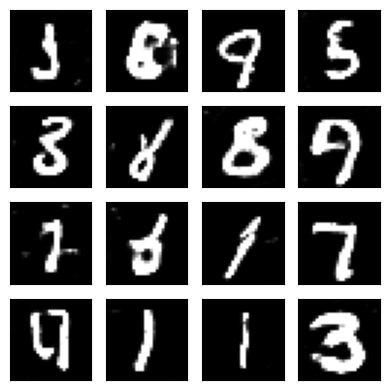

Epoch: 81/100 Discriminator Loss: 0.9224 Generator Loss: 2.2331
Epoch: 82/100 Discriminator Loss: 0.9238 Generator Loss: 2.2273
Epoch: 83/100 Discriminator Loss: 0.9252 Generator Loss: 2.2217
Epoch: 84/100 Discriminator Loss: 0.9266 Generator Loss: 2.2159
Epoch: 85/100 Discriminator Loss: 0.9279 Generator Loss: 2.2104
Epoch: 86/100 Discriminator Loss: 0.9293 Generator Loss: 2.2049
Epoch: 87/100 Discriminator Loss: 0.9306 Generator Loss: 2.1996
Epoch: 88/100 Discriminator Loss: 0.9319 Generator Loss: 2.1944
Epoch: 89/100 Discriminator Loss: 0.9332 Generator Loss: 2.1893
Epoch: 90/100 Discriminator Loss: 0.9344 Generator Loss: 2.1842


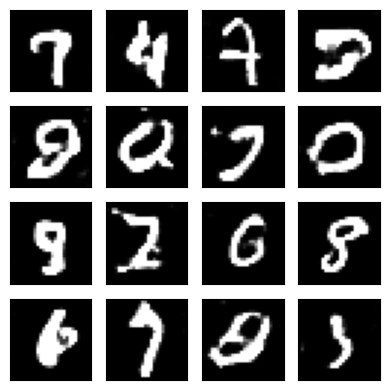

Epoch: 91/100 Discriminator Loss: 0.9357 Generator Loss: 2.1790
Epoch: 92/100 Discriminator Loss: 0.9369 Generator Loss: 2.1743
Epoch: 93/100 Discriminator Loss: 0.9381 Generator Loss: 2.1695
Epoch: 94/100 Discriminator Loss: 0.9393 Generator Loss: 2.1647
Epoch: 95/100 Discriminator Loss: 0.9404 Generator Loss: 2.1601
Epoch: 96/100 Discriminator Loss: 0.9415 Generator Loss: 2.1556
Epoch: 97/100 Discriminator Loss: 0.9427 Generator Loss: 2.1511
Epoch: 98/100 Discriminator Loss: 0.9437 Generator Loss: 2.1468
Epoch: 99/100 Discriminator Loss: 0.9448 Generator Loss: 2.1424
Epoch:100/100 Discriminator Loss: 0.9459 Generator Loss: 2.1380


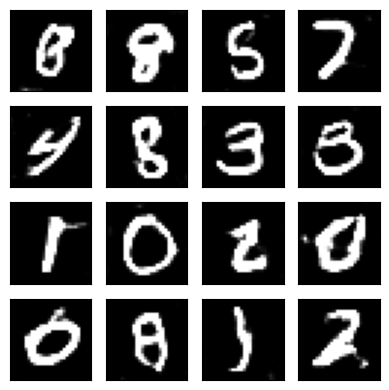

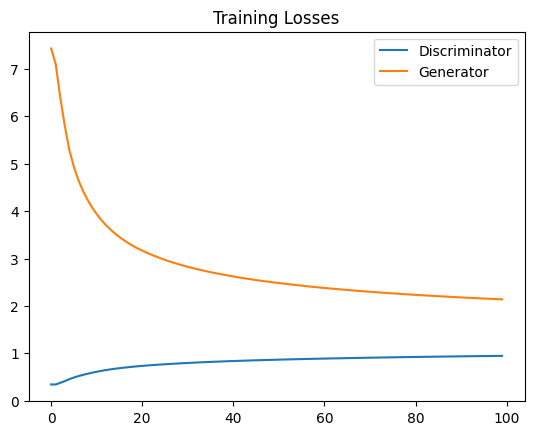

In [ ]:
train(g_learning_rate=0.0001, g_beta_1=0.9, d_learning_rate=0.001, d_beta_1=0.9, leaky_alpha=0.2);

Utilicé LeakyReLU=0.2 para el experimento anterior. Las pérdidas oscilan más, pero las imágenes generadas lucen igual de bien.

## References

https://github.com/naokishibuya/deep-learning

<a id="ref1"></a>
### [1] MNIST dataset

Yann LeCun

http://yann.lecun.com/exdb/mnist/

<a id="ref2"></a>
### [2] Deep Convolutional GANs

Udacity

https://github.com/udacity/deep-learning/blob/master/dcgan-svhn/DCGAN.ipynb

<a id="ref3"></a>
### [3] Unsupervised Representation Learning with Deep Convolutional Generative Adversarial Networks

Alec Radford & Luke Metz (indico Research), Soumith Chintala (Facebook AI Research)

https://arxiv.org/pdf/1511.06434.pdf